In [11]:
import pandas as pd

In [12]:
clus = pd.read_csv("/Users/rayyan/Desktop/honors_indep_study/Results/Clustering_Results.csv")

In [13]:
clus.head()

,particle_id,x,y,Area,frame,cluster,cluster_size,particle_type,N_active,N_passive
0,2,426.450,1012.742,120,1,2,6,passive,3,3
1,4,447.027,1013.581,74,1,2,6,active,3,3
2,5,1036.585,1014.553,94,1,5,5,active,3,2
3,6,1663.939,1013.535,57,1,6,4,active,2,2
4,10,405.876,1017.489,93,1,2,6,active,3,3


In [14]:
clus['active_fraction'] = clus['N_active'] / clus['cluster_size']

In [15]:
from scipy.spatial import cKDTree

AA_CUT = 24

rows = []
for frame, g in clus[clus['particle_type'] == 'active'].groupby('frame'):
    g = g.reset_index(drop=True)
    if len(g) < 2:
        continue
    pairs = cKDTree(g[['x', 'y']].values).query_pairs(AA_CUT, output_type='ndarray')
    if len(pairs) == 0:
        continue
    a, b = g.iloc[pairs[:, 0]], g.iloc[pairs[:, 1]]
    rows.append(pd.DataFrame({
        'frame':  frame,
        'id_1':   a['particle_id'].values, 'id_2':   b['particle_id'].values,
        'area_1': a['Area'].values,        'area_2': b['Area'].values,
    }))

aa_pairs = pd.concat(rows, ignore_index=True)
print("AA pairs:", len(aa_pairs), "across", aa_pairs['frame'].nunique(), "frames")

AA pairs: 8852 across 401 frames


In [16]:
clus.head()

,particle_id,x,y,Area,frame,cluster,cluster_size,particle_type,N_active,N_passive,active_fraction
0,2,426.450,1012.742,120,1,2,6,passive,3,3,0.5
1,4,447.027,1013.581,74,1,2,6,active,3,3,0.5
2,5,1036.585,1014.553,94,1,5,5,active,3,2,0.6
3,6,1663.939,1013.535,57,1,6,4,active,2,2,0.5
4,10,405.876,1017.489,93,1,2,6,active,3,3,0.5


In [17]:
import numpy as np, pandas as pd

TYPE = 'particle_type'                       # use 'particle_type_new' for the relabeled version
CUT = {'AA': 24, 'AP': 48, 'PP': 48}         

def contacts(g):
    xy  = g[['x', 'y']].values
    isA = (g[TYPE] == 'active').values
    i, j = np.triu_indices(len(g), 1)        # every pair in the cluster, once
    d = np.linalg.norm(xy[i] - xy[j], axis=1)
    a, b = isA[i], isA[j]
    return pd.Series({
        'cluster_num_AA_contacts': ((d <= CUT['AA']) & a & b).sum(),
        'cluster_num_AP_contacts': ((d <= CUT['AP']) & (a != b)).sum(),
        'cluster_num_PP_contacts': ((d <= CUT['PP']) & ~a & ~b).sum(),
    })

cc = clus.groupby(['frame', 'cluster']).apply(contacts).reset_index()
clus = clus.drop(columns=[c for c in cc.columns if c in clus.columns and c not in ('frame', 'cluster')]) \
           .merge(cc, on=['frame', 'cluster'], how='left')

print(clus[['cluster_num_AA_contacts', 'cluster_num_AP_contacts', 'cluster_num_PP_contacts']].describe())

       cluster_num_AA_contacts  cluster_num_AP_contacts  \
count            295616.000000            295616.000000   
mean                  0.158581                 5.108076   
std                   0.522539                 2.733547   
min                   0.000000                 0.000000   
25%                   0.000000                 2.000000   
50%                   0.000000                 4.000000   
75%                   0.000000                 7.000000   
max                   7.000000                12.000000   

       cluster_num_PP_contacts  
count            295616.000000  
mean                  2.086125  
std                   1.997493  
min                   0.000000  
25%                   1.000000  
50%                   1.000000  
75%                   3.000000  
max                  15.000000  


/var/folders/nt/7kjb9gxn32xccywytr5q936c0000gn/T/ipykernel_73523/715682357.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cc = clus.groupby(['frame', 'cluster']).apply(contacts).reset_index()


In [18]:
# 1. with all cutoffs equal, the three types should add up to all close pairs
tot = clus[['cluster_num_AA_contacts','cluster_num_AP_contacts','cluster_num_PP_contacts']].sum(axis=1)
print("max possible pairs exceeded:",
      (tot > clus['cluster_size'] * (clus['cluster_size'] - 1) / 2).sum())

# 2. a cluster with no actives can't have AA or AP contacts
print(clus[clus['N_active'] == 0][['cluster_num_AA_contacts','cluster_num_AP_contacts']].sum())

max possible pairs exceeded: 0
cluster_num_AA_contacts    0
cluster_num_AP_contacts    0
dtype: int64


In [19]:
clus.head()

,particle_id,x,y,Area,frame,cluster,cluster_size,particle_type,N_active,N_passive,active_fraction,cluster_num_AA_contacts,cluster_num_AP_contacts,cluster_num_PP_contacts
0,2,426.450,1012.742,120,1,2,6,passive,3,3,0.5,0,9,3
1,4,447.027,1013.581,74,1,2,6,active,3,3,0.5,0,9,3
2,5,1036.585,1014.553,94,1,5,5,active,3,2,0.6,0,4,1
3,6,1663.939,1013.535,57,1,6,4,active,2,2,0.5,0,3,1
4,10,405.876,1017.489,93,1,2,6,active,3,3,0.5,0,9,3


24 active-active pairs in frame 51


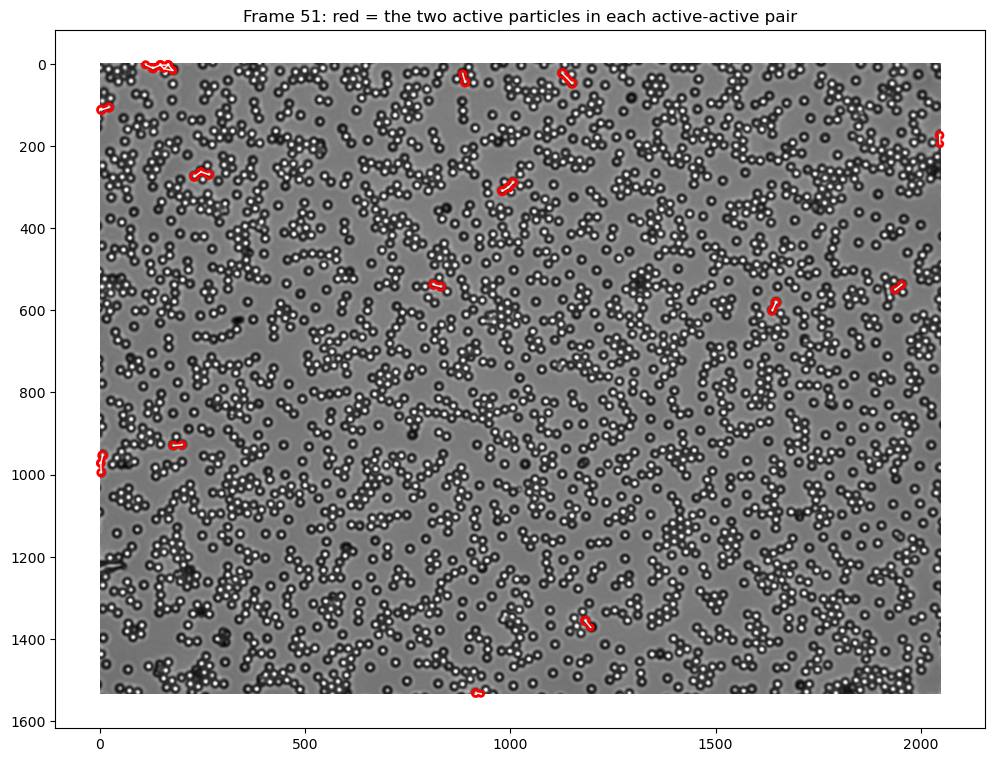

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

FRAME = 51
IMG = '/Users/rayyan/Desktop/honors_indep_study/0.07 s.png'

pf = aa_pairs[aa_pairs['frame'] == FRAME]
pos = clus[clus['frame'] == FRAME].set_index('particle_id')[['x', 'y', 'Area']]
print(len(pf), "active-active pairs in frame", FRAME)

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(plt.imread(IMG), cmap='gray')

for _, p in pf.iterrows():
    pts = []
    for pid in (p['id_1'], p['id_2']):
        r = pos.loc[pid]
        rad = np.sqrt(r['Area'] / np.pi) + 4
        ax.add_patch(Circle((r['x'], r['y']), rad, fill=False, edgecolor='red', linewidth=2))
        pts.append((r['x'], r['y']))
    ax.plot([pts[0][0], pts[1][0]], [pts[0][1], pts[1][1]], color='white', linewidth=1)

ax.set_title(f'Frame {FRAME}: red = the two active particles in each active-active pair')
plt.show()

In [21]:
import numpy as np
import pandas as pd

n_active = (clus['particle_type'] == 'active').sum()

# every active particle that is in at least one AA pair (counted once per frame)
ids = pd.concat([
    aa_pairs[['frame', 'id_1']].rename(columns={'id_1': 'pid'}),
    aa_pairs[['frame', 'id_2']].rename(columns={'id_2': 'pid'}),
]).drop_duplicates()
in_pair = len(ids)

# particles that would change: larger area in a pair, ties skipped
p = aa_pairs[aa_pairs['area_1'] != aa_pairs['area_2']].copy()
p['pid'] = np.where(p['area_1'] > p['area_2'], p['id_1'], p['id_2'])
changed = len(p[['frame', 'pid']].drop_duplicates())

print("active particles:", n_active)
print("in an AA pair:", in_pair, round(in_pair / n_active * 100, 2), "% of active")
print("changed to passive:", changed, round(changed / n_active * 100, 2), "% of active")
print("changed:", round(changed / len(clus) * 100, 2), "% of all particles")

active particles: 148667
in an AA pair: 14627 9.84 % of active
changed to passive: 7854 5.28 % of active
changed: 2.66 % of all particles


In [22]:
OUT = '/Users/rayyan/Desktop/honors_indep_study/Results/Clustering_Results_week2.csv'
clus.to_csv(OUT, index=False)
print("saved:", OUT, clus.shape)

# also save the AA pairs (only works while aa_pairs is still defined in this session)
aa_pairs.to_csv('/Users/rayyan/Desktop/honors_indep_study/Results/AA_pairs_24px.csv', index=False)
print("saved AA pairs:", aa_pairs.shape)

saved: /Users/rayyan/Desktop/honors_indep_study/Results/Clustering_Results_week2.csv (295616, 14)
saved AA pairs: (8852, 5)
